# 09 - What Each Crop Needs

**Owner:** Mostafa Elsherif
**Source:** FAO/IIASA GAEZ v5 (in the challenge resources), plus our own Sentinel-2 signals from notebook 08
**Outputs:**

| File | Rows | Key | What it holds |
|---|---|---|---|
| `crops_table.csv` | 8 | `crop` | What each candidate crop needs in our pilot area: season, planting day, cycle length, irrigation water, heat limits, suitability, yield |
| `crops_cell.csv` | 560 | `cell_id` | The same crop needs for every 1 km cell |
| `crops_actual_2020.csv` | one row per crop | `crop` | What farmers in our area **actually** harvested in 2020 |

Figures are saved to `figures/09_*.png`.

## Why this step exists

Notebook 08 described the **land**: when each field is green, when it is empty, how much water each month needs. It said nothing about crops, on purpose.

This notebook describes the other side: the **crops**. For each of our 8 candidate crops it answers:

1. **When does it grow?** Planting day and cycle length.
2. **How much irrigation water does it need here?** In millimetres over its whole cycle.
3. **Does heat limit it here?**
4. **How suitable is the land, and how much can it yield?** (from notebook 06)
5. **Do farmers here actually grow it?** And how much do they really harvest?

Notebook 10 then matches land and crops.

## Every number comes from the challenge resources

All crop requirements come from **GAEZ v5**, which is in the official challenge resource list. We do not copy crop tables from textbooks or other websites. That keeps every number traceable to one documented source, and it means the team can re-run this notebook and get the same answer.

## The GAEZ layers we use

| Layer | Code | Resolution | What it is |
|---|---|---|---|
| Beginning of crop growth cycle | `RES02-CBD` | ~10 km | day of the year the crop is sown, for the best yield |
| Length of crop growth cycle | `RES02-CYL` | ~10 km | days from sowing to harvest |
| Thermal yield constraint | `RES02-FC1` | ~10 km | how much heat or cold cuts the yield (10000 = no loss) |
| Net irrigation requirement | `RES05-WDC` | ~10 km | water the crop needs beyond rain, in mm, on current cropland |
| Multi-cropping class | `RES01-MCI` | ~10 km | how many crops a year the climate allows, with irrigation |
| Harvested area, 2020 | `RES06-HAR` | ~10 km | real harvested area, from national statistics downscaled to the map |
| Yield, 2020 | `RES06-YLD` | ~10 km | real yield in tonnes per hectare |

All modelled layers use the same settings as notebook 06: **2001-2020 climate (AgERA5), irrigated, high input**.

The ~10 km layers are coarse, but our pilot area is small and uniform: a 10 km pixel covers many of our 1 km cells. These layers describe the crop in our area as a whole, not field by field.

## One problem we found before writing this notebook

FAO's online catalog lists only a few crops for the 2001-2020 period in `RES02-CBD` and `RES02-CYL`, and wheat, maize and cotton are not among them. We checked the storage bucket itself and found **all 8 crops present for every layer**. The catalog is incomplete; the data is not. We read the files directly, as in notebook 06.

## Crop codes differ between GAEZ layers

GAEZ uses different crop codes in different themes. This table keeps them straight:

| Crop | Theme 4/5 (RES05) | Theme 3 (RES02) | Theme 6 (RES06, actual) |
|---|---|---|---|
| Wheat | WHE | WHEA | WHE |
| Maize | MZE | MAIZ | MZE |
| Rice (wetland) | RCW | RICW | RCW |
| Cotton | COT | COTT | COT |
| Alfalfa | ALF | ALFA | FDD (all fodder crops) |
| Sugar beet | SUB | SUGB | SUB |
| Potato | WPO | WPOT | POT (white and sweet potato) |
| Soybean | SOY | SOYB | SOY |

Two of the actual-harvest codes are broader than our crop: alfalfa is reported inside **all fodder crops** (which in Egypt is mostly berseem clover), and potato inside **white and sweet potato together**. We keep that in mind when comparing.

In [1]:
%pip install rasterio pyproj scipy -q

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio
from rasterio.windows import from_bounds
from rasterio.transform import rowcol
from pyproj import Transformer

os.environ["GDAL_DISABLE_READDIR_ON_OPEN"] = "EMPTY_DIR"
os.environ["CPL_VSIL_CURL_ALLOWED_EXTENSIONS"] = ".tif"

REPO = Path.cwd()
if REPO.name == "notebooks":
    REPO = REPO.parent                      # works for everyone, not just one laptop
P   = REPO / "data" / "processed"
FIG = REPO / "figures"
FIG.mkdir(exist_ok=True)

# GAEZ v5 storage. Set the environment variable GAEZ_BASE to a local folder to work offline.
GAEZ_BASE = os.environ.get("GAEZ_BASE",
    "https://storage.googleapis.com/fao-gismgr-gaez-v5-data/DATA/GAEZ-V5/MAPSET")

W, S, E, N = 30.70, 31.05, 30.91, 31.30
PAD = 0.15                                   # wide enough to hold whole ~10 km pixels
assert 31 <= S < N < 32 and 30 <= W < E < 31, "lat/lon swapped"

MONTHS = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]

CROPS = pd.DataFrame([
    # crop        RES05  RES02   RES06
    ("wheat",     "WHE", "WHEA", "WHE"),
    ("maize",     "MZE", "MAIZ", "MZE"),
    ("rice",      "RCW", "RICW", "RCW"),
    ("cotton",    "COT", "COTT", "COT"),
    ("alfalfa",   "ALF", "ALFA", "FDD"),
    ("sugarbeet", "SUB", "SUGB", "SUB"),
    ("potato",    "WPO", "WPOT", "POT"),
    ("soybean",   "SOY", "SOYB", "SOY"),
], columns=["crop", "c05", "c02", "c06"]).set_index("crop")

grid = pd.read_csv(P / "grid_1km.csv")
gz   = pd.read_csv(P / "gaez_static.csv")
sc   = pd.read_csv(P / "signals_cell.csv")
sam  = pd.read_csv(P / "signals_area_month.csv")
assert len(grid) == len(gz) == len(sc) == 560 and len(sam) == 12

t = Transformer.from_crs("EPSG:32636", "EPSG:4326", always_xy=True)
lo0, la0 = t.transform(grid.x_min_m.values, grid.y_min_m.values)
lo1, la1 = t.transform(grid.x_max_m.values, grid.y_max_m.values)
print("inputs OK:", len(grid), "cells | GAEZ source:", GAEZ_BASE.split("/")[2] if "://" in GAEZ_BASE else GAEZ_BASE)

inputs OK: 560 cells | GAEZ source: storage.googleapis.com


## Step 1 - Read the GAEZ layers

One function does all the reading. For each layer it:

1. opens the file by URL (only the bytes for our window come down - no 200 MB download)
2. reads a window around our area, padded so whole 10 km pixels are included
3. turns `nodata` into empty values
4. returns the **mean of every GAEZ pixel touching each 1 km cell**, the same method as notebook 06 - except for **class** layers, where it returns the **most common class**. Averaging class 4 ("double cropping") with class 5 ("double cropping with rice") would give 4.5, which is not a class at all.

`nodata` is not the same in every layer: -9 in most, 0 in the calendar and yield layers (where 0 would be meaningless anyway). The function takes the layer's own `nodata` plus any extra value we pass.

**Irrigation need of exactly 0 mm is also treated as missing.** On our first run, the same 22 cells had a need of 0 mm for six different crops, all in one rectangular block on the eastern edge - the footprint of a single ~10 km GAEZ pixel. A need of zero is physically impossible here: notebook 08 showed that July, August and September get no rain at all. The layer is computed only on GAEZ's own map of current cropland, so a pixel outside that map comes out as 0. It means "not evaluated", not "no water needed".

In [3]:
def read_layer(ms, code, extra_nodata=(), scale=1.0, how="mean"):
    url = f"{GAEZ_BASE}/{ms}/GAEZ-V5.{ms}.{code}.tif"
    with rasterio.open(url) as src:
        win = from_bounds(W - PAD, S - PAD, E + PAD, N + PAD, src.transform)
        a   = src.read(1, window=win).astype("float64")
        tf  = src.window_transform(win)
        nod = src.nodata
    if nod is not None:
        a[a == nod] = np.nan
    for v in extra_nodata:
        a[a == v] = np.nan
    a[a < 0] = np.nan
    a *= scale

    r_top, c_left  = rowcol(tf, lo0, la1)
    r_bot, c_right = rowcol(tf, lo1, la0)
    r_top, c_left, r_bot, c_right = map(np.asarray, (r_top, c_left, r_bot, c_right))
    H, Wd = a.shape
    vals = np.full(len(grid), np.nan)
    for i in range(len(grid)):
        r0, r1 = max(0, min(r_top[i], r_bot[i])), min(H,  max(r_top[i], r_bot[i]) + 1)
        c0, c1 = max(0, min(c_left[i], c_right[i])), min(Wd, max(c_left[i], c_right[i]) + 1)
        if r1 > r0 and c1 > c0:
            block = a[r0:r1, c0:c1]
            ok = block[np.isfinite(block)]
            if ok.size:
                if how == "mode":                      # classes: most common value, never an average
                    u, n = np.unique(ok, return_counts=True)
                    vals[i] = u[n.argmax()]
                else:
                    vals[i] = ok.mean()
    pix_deg = abs(tf.a), abs(tf.e)
    return vals, pix_deg

HIST = "HP0120.AGERA5.HIST"
cell = grid[["cell_id"]].copy()
log  = []

for crop, r in CROPS.iterrows():
    cell[f"plant_doy_{crop}"],  _ = read_layer("RES02-CBD", f"{HIST}.{r.c02}.HILM", extra_nodata=(0,))
    cell[f"cycle_days_{crop}"], _ = read_layer("RES02-CYL", f"{HIST}.{r.c02}.HILM", extra_nodata=(0,))
    cell[f"thermal_{crop}"],    _ = read_layer("RES02-FC1", f"{HIST}.{r.c02}.HILM")
    cell[f"irrig_mm_{crop}"],   _ = read_layer("RES05-WDC", f"{HIST}.{r.c05}.HILM", extra_nodata=(0,))
    log.append((crop, *[int(cell[f"{v}_{crop}"].isna().sum()) for v in ["plant_doy", "cycle_days", "thermal", "irrig_mm"]]))

cell["mci_class"], mci_pix = read_layer("RES01-MCI", HIST, extra_nodata=(0,), how="mode")

print("missing cells per layer (of 560):")
print(pd.DataFrame(log, columns=["crop", "plant_doy", "cycle_days", "thermal", "irrig_mm"]).to_string(index=False))
print(f"\nmulti-cropping class missing: {int(cell.mci_class.isna().sum())}")
print(f"GAEZ pixel size: {mci_pix[0]:.4f} x {mci_pix[1]:.4f} degrees")

missing cells per layer (of 560):
     crop  plant_doy  cycle_days  thermal  irrig_mm
    wheat          0           0        0        22
    maize          0           0        0        22
     rice          0           0        0        22
   cotton          0           0        0         0
  alfalfa          0           0        0        22
sugarbeet          0           0        0         0
   potato          0           0        0        22
  soybean          0           0        0        22

multi-cropping class missing: 0
GAEZ pixel size: 0.0833 x 0.0833 degrees


In [4]:
# Sanity checks on units before anything is interpreted
pd_cols = [c for c in cell if c.startswith("plant_doy_")]
cy_cols = [c for c in cell if c.startswith("cycle_days_")]
th_cols = [c for c in cell if c.startswith("thermal_")]
ir_cols = [c for c in cell if c.startswith("irrig_mm_")]

checks = {
    "planting day inside 1-365":          cell[pd_cols].stack().dropna().between(1, 366).all(),
    "cycle length inside 1-365 days":     cell[cy_cols].stack().dropna().between(1, 366).all(),
    "thermal factor inside 0-10000":      cell[th_cols].stack().dropna().between(0, 10000).all(),
    "irrigation need inside 0-3000 mm":   cell[ir_cols].stack().dropna().between(0, 3000).all(),
    "multi-cropping class inside 1-8":    cell.mci_class.dropna().between(1, 8).all(),
}
for k, v in checks.items():
    print(f"  {'PASS' if v else 'FAIL'}  {k}")
assert all(checks.values()), "a GAEZ layer is outside its documented range - stop and check units"

  PASS  planting day inside 1-365
  PASS  cycle length inside 1-365 days
  PASS  thermal factor inside 0-10000
  PASS  irrigation need inside 0-3000 mm
  PASS  multi-cropping class inside 1-8


## Step 2 - The crop table for our area

For each crop we summarise the 560 cells into one row: the **median** cell, and the **spread** (lowest to highest cell) so we can see whether one number is enough for the whole area.

**Planting day is a circular number.** Day 360 and day 5 are ten days apart, not 355. A plain average of 360 and 5 gives 182 - midsummer - which is nonsense. So the planting day is averaged as an angle on a circle, then turned back into a day.

**Season.** We call a crop *winter* if the middle of its cycle falls between November and April, *summer* if it falls between May and October, and *all-year* if its cycle is longer than 300 days (alfalfa is a perennial forage).

In [5]:
def circ_mean_doy(d):
    d = np.asarray(d, float); d = d[np.isfinite(d)]
    if len(d) == 0:
        return np.nan
    ang = 2 * np.pi * (d - 1) / 365
    m = np.arctan2(np.sin(ang).mean(), np.cos(ang).mean())
    return (m % (2 * np.pi)) * 365 / (2 * np.pi) + 1

def doy_to_month(d):
    return (pd.Timestamp(2021, 1, 1) + pd.Timedelta(days=int(round(d)) - 1)).month

rows = []
for crop in CROPS.index:
    p   = circ_mean_doy(cell[f"plant_doy_{crop}"])
    cyc = cell[f"cycle_days_{crop}"].median()
    harvest = ((p - 1 + cyc) % 365) + 1
    mid     = ((p - 1 + cyc / 2) % 365) + 1
    mid_m   = doy_to_month(mid)
    season  = "all-year" if cyc > 300 else ("winter" if mid_m in (11, 12, 1, 2, 3, 4) else "summer")
    rows.append({
        "crop": crop,
        "season": season,
        "plant_doy": round(p),
        "plant_month": doy_to_month(p),
        "cycle_days": cyc,
        "harvest_doy": round(harvest),
        "harvest_month": doy_to_month(harvest),
        "irrig_mm": cell[f"irrig_mm_{crop}"].median(),
        "irrig_mm_min": cell[f"irrig_mm_{crop}"].min(),
        "irrig_mm_max": cell[f"irrig_mm_{crop}"].max(),
        "thermal_factor": cell[f"thermal_{crop}"].median() / 10000,
        "suitability": gz[f"si_{crop}"].median(),
        "suit_class": gz[f"class_{crop}"].median(),
        "attainable_kg_ha": gz[f"yield_{crop}"].median(),
    })
crops = pd.DataFrame(rows).set_index("crop")
crops["irrig_mm_per_day"] = crops.irrig_mm / crops.cycle_days

show = crops.copy()
show["plant"]   = [MONTHS[m - 1] for m in show.plant_month]
show["harvest"] = [MONTHS[m - 1] for m in show.harvest_month]
print(show[["season", "plant", "plant_doy", "cycle_days", "harvest", "irrig_mm", "irrig_mm_per_day",
            "thermal_factor", "suitability", "attainable_kg_ha"]].round(2).to_string())
print("\nspread of irrigation need across the 560 cells (mm):")
print(crops[["irrig_mm_min", "irrig_mm", "irrig_mm_max"]].round(0).to_string())

             season plant  plant_doy  cycle_days harvest  irrig_mm  irrig_mm_per_day  thermal_factor  suitability  attainable_kg_ha
crop                                                                                                                               
wheat        winter   Dec        346       150.0     May     360.0              2.40            0.99        76.43           4522.99
maize        summer   Feb         58       180.0     Aug     724.0              4.02            1.00        65.11          10747.62
rice         summer   Mar         82       150.0     Aug     669.0              4.46            1.00        57.85           5663.77
cotton       summer   Apr        107       180.0     Oct     657.0              3.65            1.00        63.50           1010.27
alfalfa    all-year   Jan          1       360.0     Dec    1132.0              3.14            1.00        59.89          15386.85
sugarbeet    summer   Jan         28       195.0     Aug     629.5          

**How to read `thermal_factor`.** It is the share of the yield that survives the temperature conditions: **1.00 means heat and cold cost nothing**, 0.80 means temperature alone removes 20% of the potential yield. It is computed for the best sowing date, so it shows what temperature does even when the farmer times the crop well.

**Why `irrig_mm_per_day` matters.** A long crop needs more water in total simply because it stands in the field longer. Dividing by cycle length shows how *thirsty* a crop is per day it occupies the land, which is fairer when comparing a 100-day crop with a 200-day one.

## Step 3 - Does the GAEZ calendar match what the satellites see?

GAEZ gives the **model's best** sowing date. Our Sentinel-2 signals (notebook 08) show when fields are **actually** empty: a spring gap in May and an autumn gap in September-October.

If GAEZ and the satellites describe the same farming system, then:

- **winter crops** should be harvested near the **spring gap** and sown near the **autumn gap**
- **summer crops** should be sown near the **spring gap** and harvested near the **autumn gap**

This is an independent check: GAEZ never saw our Sentinel-2 images, and our images know nothing about GAEZ.

In [6]:
spring_gap_doy = circ_mean_doy([pd.Timestamp(2021, int(mo), 15).dayofyear for mo in sc.spring_gap_month])
autumn_gap_doy = circ_mean_doy([pd.Timestamp(2021, int(mo), 15).dayofyear for mo in sc.autumn_gap_month])

def doy_dist(a, b):
    d = abs(a - b) % 365
    return min(d, 365 - d)

cmp_rows = []
for crop, r in crops.iterrows():
    if r.season == "winter":
        cmp_rows.append((crop, r.season, "sow vs autumn gap",   doy_dist(r.plant_doy,   autumn_gap_doy)))
        cmp_rows.append((crop, r.season, "harvest vs spring gap", doy_dist(r.harvest_doy, spring_gap_doy)))
    elif r.season == "summer":
        cmp_rows.append((crop, r.season, "sow vs spring gap",   doy_dist(r.plant_doy,   spring_gap_doy)))
        cmp_rows.append((crop, r.season, "harvest vs autumn gap", doy_dist(r.harvest_doy, autumn_gap_doy)))
cmp = pd.DataFrame(cmp_rows, columns=["crop", "season", "comparison", "days_apart"])

print(f"observed spring gap: day {spring_gap_doy:.0f} ({MONTHS[doy_to_month(spring_gap_doy)-1]}) | "
      f"observed autumn gap: day {autumn_gap_doy:.0f} ({MONTHS[doy_to_month(autumn_gap_doy)-1]})\n")
print(cmp.round(0).to_string(index=False))
print(f"\nmedian distance: {cmp.days_apart.median():.0f} days | within 45 days: "
      f"{(cmp.days_apart <= 45).sum()} of {len(cmp)}")
print("\nmedian distance by type of date:")
print(cmp.assign(kind=cmp.comparison.str.split().str[0]).groupby("kind").days_apart.median().round(0).to_string())

observed spring gap: day 135 (May) | observed autumn gap: day 278 (Oct)

     crop season            comparison  days_apart
    wheat winter     sow vs autumn gap        68.0
    wheat winter harvest vs spring gap         4.0
    maize summer     sow vs spring gap        77.0
    maize summer harvest vs autumn gap        40.0
     rice summer     sow vs spring gap        53.0
     rice summer harvest vs autumn gap        46.0
   cotton summer     sow vs spring gap        28.0
   cotton summer harvest vs autumn gap         9.0
sugarbeet summer     sow vs spring gap       107.0
sugarbeet summer harvest vs autumn gap        55.0
   potato winter     sow vs autumn gap        84.0
   potato winter harvest vs spring gap        42.0
  soybean summer     sow vs spring gap        71.0
  soybean summer harvest vs autumn gap        79.0

median distance: 54 days | within 45 days: 5 of 14

median distance by type of date:
kind
harvest    42.0
sow        71.0


### Why sowing dates can disagree while harvest dates agree

GAEZ chooses each crop's sowing date to give **that crop alone** its best possible yield. It does not know that the field is still occupied by the previous crop. In a two-crop rotation, a summer crop cannot be sown until the winter crop is harvested, however good an earlier date would be for it.

The satellites show what the rotation actually leaves. The two observed gaps split the year into two **windows**:

- the **summer window**: from the spring gap to the autumn gap
- the **winter window**: from the autumn gap to the next spring gap

We compare each crop's GAEZ cycle length with the window it would have to fit into.

In [7]:
summer_window = (autumn_gap_doy - spring_gap_doy) % 365
winter_window = 365 - summer_window
print(f"summer window (spring gap -> autumn gap): {summer_window:.0f} days")
print(f"winter window (autumn gap -> spring gap): {winter_window:.0f} days\n")

fit = crops[["season", "cycle_days"]].copy()
fit["window_days"] = np.where(fit.season == "summer", summer_window,
                      np.where(fit.season == "winter", winter_window, np.nan))
fit["fits_window"] = fit.cycle_days <= fit.window_days
# signed: positive = GAEZ sows that many days BEFORE the field is free, negative = after
signed = [((spring_gap_doy - d + 182) % 365) - 182 for d in crops.plant_doy]
fit["sown_before_field_opens_days"] = np.where(fit.season == "summer", signed, np.nan)
print(fit.round(0).to_string())

summer window (spring gap -> autumn gap): 143 days
winter window (autumn gap -> spring gap): 222 days

             season  cycle_days  window_days  fits_window  sown_before_field_opens_days
crop                                                                                   
wheat        winter       150.0        222.0         True                           NaN
maize        summer       180.0        143.0        False                          77.0
rice         summer       150.0        143.0        False                          53.0
cotton       summer       180.0        143.0        False                          28.0
alfalfa    all-year       360.0          NaN        False                           NaN
sugarbeet    summer       195.0        143.0        False                         107.0
potato       winter       180.0        222.0         True                           NaN
soybean      summer       135.0        143.0         True                          71.0


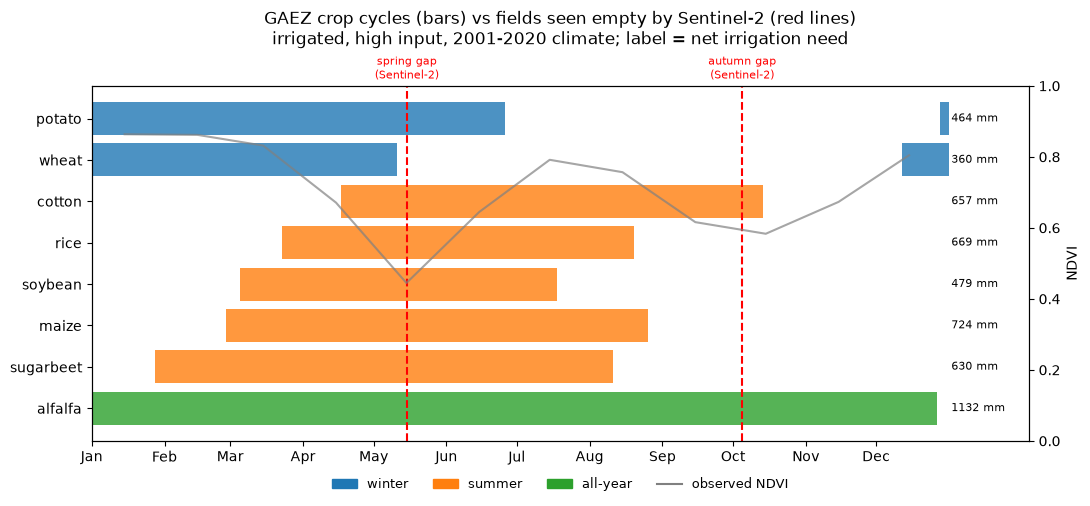

In [8]:
fig, ax = plt.subplots(figsize=(11, 5.2))
order = crops.sort_values(["season", "plant_doy"]).index
colors = {"winter": "tab:blue", "summer": "tab:orange", "all-year": "tab:green"}

for y, crop in enumerate(order):
    r = crops.loc[crop]
    start, length = r.plant_doy, min(r.cycle_days, 365)
    if start + length <= 366:
        ax.barh(y, length, left=start, color=colors[r.season], alpha=0.8)
    else:                                        # wraps past 31 December
        ax.barh(y, 366 - start, left=start, color=colors[r.season], alpha=0.8)
        ax.barh(y, start + length - 366, left=1, color=colors[r.season], alpha=0.8)
    ax.text(367, y, f"{r.irrig_mm:.0f} mm", va="center", fontsize=8)

for d, lab in [(spring_gap_doy, "spring gap\n(Sentinel-2)"), (autumn_gap_doy, "autumn gap\n(Sentinel-2)")]:
    ax.axvline(d, color="red", ls="--", lw=1.5)
    ax.text(d, 1.01, lab, color="red", ha="center", va="bottom", fontsize=8, transform=ax.get_xaxis_transform())

ax2 = ax.twinx()
mid_doy = [pd.Timestamp(2021, m, 15).dayofyear for m in range(1, 13)]
ax2.plot(mid_doy, sam.ndvi_area_median, color="gray", lw=1.5, alpha=0.7, label="observed NDVI (notebook 08)")
ax2.set_ylim(0, 1); ax2.set_ylabel("NDVI")

ax.set_yticks(range(len(order)), order)
ax.set_xlim(1, 400)
ax.set_xticks([pd.Timestamp(2021, m, 1).dayofyear for m in range(1, 13)], MONTHS)
ax.set_title("GAEZ crop cycles (bars) vs fields seen empty by Sentinel-2 (red lines)\nirrigated, high input, 2001-2020 climate; label = net irrigation need", pad=30)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=s) for s, c in colors.items()] +
          [plt.Line2D([], [], color="gray", label="observed NDVI")],
          loc="upper center", bbox_to_anchor=(0.5, -0.07), ncol=4, frameon=False, fontsize=9)
plt.tight_layout()
plt.savefig(FIG / "09_crop_calendar.png", dpi=150)
plt.show()

## Step 4 - How many crops a year does the climate allow?

GAEZ's multi-cropping class says how many crops per year the climate supports **with irrigation**. Notebook 08 found from Sentinel-2 that **556 of 560 cells** already grow two crops a year. If GAEZ agrees, the model and the satellites describe the same land.

| Class | Meaning |
|---|---|
| 1 | no cropping |
| 2 | single cropping |
| 3 | limited double cropping |
| 4 | double cropping |
| 5 | double cropping with rice |
| 6 | double rice cropping |
| 7 | triple cropping |
| 8 | triple rice cropping |

In [9]:
MCI = {1: "no cropping", 2: "single", 3: "limited double", 4: "double", 5: "double with rice",
       6: "double rice", 7: "triple", 8: "triple rice"}
mci = cell.mci_class
print("GAEZ multi-cropping class across our 560 cells:")
for k, n in mci.value_counts().sort_index().items():
    print(f"  class {int(k)} ({MCI[int(k)]}): {n} cells")

two_plus_gaez = (mci >= 4).sum()
two_seen      = sc.two_seasons.sum()
print(f"\nGAEZ allows two or more crops a year in : {two_plus_gaez} of 560 cells")
print(f"Sentinel-2 sees two seasons a year in    : {two_seen} of 560 cells")

GAEZ multi-cropping class across our 560 cells:
  class 8 (triple rice): 560 cells

GAEZ allows two or more crops a year in : 560 of 560 cells
Sentinel-2 sees two seasons a year in    : 556 of 560 cells


## Step 5 - What do farmers here actually grow?

Everything so far is a **model**: what GAEZ calculates the land and climate can do. Theme 6 of GAEZ is different. It takes **real harvest statistics for 2020** and spreads them onto the map. That lets us check the model against reality.

The values are harvested area per ~10 km pixel, stored in **thousands of hectares** (scale factor 1000, from the FAO catalog). To get the area inside our 560 km², we turn each pixel into a **density** (harvested hectares per hectare of land) and multiply by each 1 km cell's 100 ha.

Harvested area can be larger than land area: a field cropped twice a year is counted twice. That is why we report each crop as a **share of all harvested area**, not of land.

We use the **irrigated** layer (`WSI`), because our area is fully irrigated.

In [10]:
EXTRA = [("tomato", "TOM"), ("other vegetables", "OVG"), ("barley", "BRL"),
         ("sugarcane", "SUC"), ("sunflower", "SFL")]

def harvested_ha(code06):
    v, (dx, dy) = read_layer("RES06-HAR", f"{code06}.WSI", scale=1000.0)   # ha per GAEZ pixel
    lat = grid.lat.values
    pix_ha = (dx * 111.32 * np.cos(np.radians(lat))) * (dy * 110.57) * 100    # km2 -> ha
    return np.nansum(v / pix_ha * 100.0)                                       # 100 ha per 1 km cell

def actual_yield(code06):
    v, _ = read_layer("RES06-YLD", f"{code06}.WSI", extra_nodata=(0,))
    return np.nanmedian(v) if np.isfinite(v).any() else np.nan

total_ha = harvested_ha("ALL")
act = []
for crop, r in CROPS.iterrows():
    act.append((crop, r.c06, harvested_ha(r.c06), actual_yield(r.c06)))
for name, c in EXTRA:
    act.append((name, c, harvested_ha(c), actual_yield(c)))

actual = pd.DataFrame(act, columns=["crop", "gaez_code", "harvested_ha", "yield_t_ha"]).set_index("crop")
actual["share_of_harvest_pct"] = actual.harvested_ha / total_ha * 100
actual["is_candidate"] = actual.index.isin(CROPS.index)

print(f"all irrigated harvested area in our 560 km2 (2020): {total_ha:,.0f} ha  "
      f"= {total_ha / 56000:.2f} harvests per hectare of land")
print(actual.sort_values("harvested_ha", ascending=False).round(2).to_string())
print(f"\nour 8 candidates cover {actual[actual.is_candidate].share_of_harvest_pct.sum():.1f}% of all harvested area")

all irrigated harvested area in our 560 km2 (2020): 87,533 ha  = 1.56 harvests per hectare of land
                 gaez_code  harvested_ha  yield_t_ha  share_of_harvest_pct  is_candidate
crop                                                                                    
sugarbeet              SUB      17375.39       68.28                 19.85          True
wheat                  WHE      17119.65        7.34                 19.56          True
rice                   RCW      15677.17       11.04                 17.91          True
maize                  MZE       6552.04        7.36                  7.49          True
potato                 POT       3526.89       31.15                  4.03          True
other vegetables       OVG       2903.48       62.63                  3.32         False
cotton                 COT       2279.15        3.19                  2.60          True
alfalfa                FDD       2257.82       26.19                  2.58          True
tomato     

### Does the GAEZ suitability ranking match what farmers grow?

If the suitability model is useful, the crops it rates highly should tend to be the ones farmers actually plant. We compare the **rank** of each candidate crop by suitability with its rank by real harvested area. We use a rank (Spearman) correlation because the two scales are completely different.

With only 8 crops this is a coarse check, not a proof, and we read it that way.

           suitability  attainable_kg_ha  share_of_harvest_pct  yield_t_ha
crop                                                                      
sugarbeet        30.00           2710.64                 19.85       68.28
wheat            76.43           4522.99                 19.56        7.34
rice             57.85           5663.77                 17.91       11.04
maize            65.11          10747.62                  7.49        7.36
potato           46.28           6752.86                  4.03       31.15
cotton           63.50           1010.27                  2.60        3.19
alfalfa          59.89          15386.85                  2.58       26.19
soybean          57.72           3269.86                  0.04        4.40

Spearman rank correlation, suitability vs actual share: rho = +0.00 (p = 1.00, n = 8)
the same without sugar beet                          : rho = +0.50 (p = 0.25, n = 7)


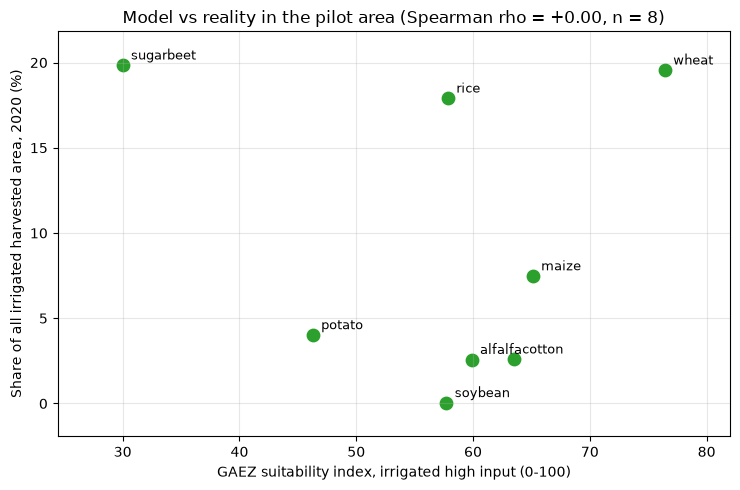

In [11]:
from scipy.stats import spearmanr
cmpx = crops[["suitability", "attainable_kg_ha"]].join(actual[["share_of_harvest_pct", "yield_t_ha"]])
rho = spearmanr(cmpx.suitability, cmpx.share_of_harvest_pct)
print(cmpx.sort_values("share_of_harvest_pct", ascending=False).round(2).to_string())
print(f"\nSpearman rank correlation, suitability vs actual share: rho = {rho.statistic:+.2f} (p = {rho.pvalue:.2f}, n = 8)")
nosb = cmpx.drop("sugarbeet")
rho7 = spearmanr(nosb.suitability, nosb.share_of_harvest_pct)
print(f"the same without sugar beet                          : rho = {rho7.statistic:+.2f} (p = {rho7.pvalue:.2f}, n = 7)")

fig, ax = plt.subplots(figsize=(7.5, 5))
ax.scatter(cmpx.suitability, cmpx.share_of_harvest_pct, s=80, color="tab:green")
for c, r in cmpx.iterrows():
    ax.annotate(c, (r.suitability, r.share_of_harvest_pct), textcoords="offset points", xytext=(6, 4), fontsize=9)
ax.set_xlabel("GAEZ suitability index, irrigated high input (0-100)")
ax.set_ylabel("Share of all irrigated harvested area, 2020 (%)")
ax.set_title(f"Model vs reality in the pilot area (Spearman rho = {rho.statistic:+.2f}, n = 8)")
ax.grid(alpha=0.3)
ax.margins(x=0.12, y=0.10)
plt.tight_layout()
plt.savefig(FIG / "09_suitability_vs_actual.png", dpi=150)
plt.show()

## Step 6 - The sugar beet question

Notebook 06 found that GAEZ rates **sugar beet the lowest** of our 8 crops in this area. We said we would not let the tool discourage a crop on the model's word alone until we checked what farmers really do. Step 5 gives us that check.

In [12]:
sb = actual.loc["sugarbeet"]
rank_area = int(actual[actual.is_candidate].harvested_ha.rank(ascending=False)["sugarbeet"])
rank_suit = int(crops.suitability.rank(ascending=False)["sugarbeet"])
print(f"sugar beet - GAEZ suitability : {crops.loc['sugarbeet', 'suitability']:.1f} / 100  (rank {rank_suit} of 8)")
print(f"sugar beet - real harvest 2020: {sb.harvested_ha:,.0f} ha = {sb.share_of_harvest_pct:.1f}% of all harvested area (rank {rank_area} of 8)")
print(f"sugar beet - real yield 2020  : {sb.yield_t_ha:.1f} t/ha")

r_sb = crops.loc["sugarbeet"]
print(f"\nHow GAEZ models sugar beet here:")
print(f"  sown on day {r_sb.plant_doy} ({MONTHS[r_sb.plant_month-1]}), {r_sb.cycle_days:.0f} days, "
      f"harvested day {r_sb.harvest_doy} ({MONTHS[r_sb.harvest_month-1]}) -> season '{r_sb.season}'")
print(f"  thermal factor: {r_sb.thermal_factor:.2f}  (share of yield left after temperature losses)")
print(f"  for comparison, the other 7 crops: {crops.drop('sugarbeet').thermal_factor.min():.2f} to "
      f"{crops.drop('sugarbeet').thermal_factor.max():.2f}")

start, end = r_sb.plant_doy, r_sb.plant_doy + r_sb.cycle_days
crosses = any(start <= g <= end for g in (spring_gap_doy, spring_gap_doy + 365))   # handles cycles past 31 Dec
print(f"\n  GAEZ sugar beet cycle covers the observed spring gap (day {spring_gap_doy:.0f}): {crosses}")
print(f"  cells where Sentinel-2 sees fields open at that gap: {(sc.spring_gap_month == 5).sum()} of 560")

sugar beet - GAEZ suitability : 30.0 / 100  (rank 8 of 8)
sugar beet - real harvest 2020: 17,375 ha = 19.9% of all harvested area (rank 1 of 8)
sugar beet - real yield 2020  : 68.3 t/ha

How GAEZ models sugar beet here:
  sown on day 28 (Jan), 195 days, harvested day 223 (Aug) -> season 'summer'
  thermal factor: 0.50  (share of yield left after temperature losses)
  for comparison, the other 7 crops: 0.99 to 1.00

  GAEZ sugar beet cycle covers the observed spring gap (day 135): True
  cells where Sentinel-2 sees fields open at that gap: 554 of 560


### What this means

If sugar beet were really grown on the GAEZ calendar, it would be standing in the field through the spring gap, when Sentinel-2 sees almost every cell open. The sugar beet that farmers here actually harvest therefore cannot be following the GAEZ calendar. It has to fit inside one of the two windows the satellites show, and a crop that GAEZ itself finds heat-limited in summer belongs in the **winter** window.

So the low GAEZ suitability does not mean "sugar beet is a poor crop here". It means "sugar beet sown in January and grown through the summer is a poor crop here" - which is a different statement, and one the farmers' own choices agree with. Our tool must therefore **not** use GAEZ suitability alone to rule a crop out. Notebook 10 has to weigh the model against what is actually grown.

## Step 7 - Save

Final checks, then three files.

In [13]:
crops_out = crops.reset_index()
actual_out = actual.reset_index()

harvests_per_ha = total_ha / (len(grid) * 100)
checks = {
    "crops_table has 8 crops":                     len(crops_out) == 8,
    "every crop has a season":                     crops_out.season.isin(["winter", "summer", "all-year"]).all(),
    "crops_cell has 560 rows":                     len(cell) == 560 and cell.cell_id.is_unique,
    "harvested area is not negative":              (actual_out.harvested_ha.fillna(0) >= 0).all(),
    "candidate shares add up to <= 100%":          actual_out[actual_out.is_candidate].share_of_harvest_pct.sum() <= 100.5,
    "0.3-3.5 harvests per hectare (scale is right)": 0.3 <= harvests_per_ha <= 3.5,
}
for k, v in checks.items():
    print(f"  {'PASS' if v else 'FAIL'}  {k}")
assert all(checks.values()), "a check failed - do not use these files"

gaps = crops_out.columns[crops_out.isna().any()].tolist()
print(f"\n  {'WARN' if gaps else 'OK  '}  missing values in crops_table columns: {gaps if gaps else 'none'}")

crops_out.to_csv(P / "crops_table.csv", index=False)
cell.to_csv(P / "crops_cell.csv", index=False)
actual_out.to_csv(P / "crops_actual_2020.csv", index=False)
for f in ["crops_table.csv", "crops_cell.csv", "crops_actual_2020.csv"]:
    print(f"saved {f:24s} {pd.read_csv(P / f).shape}")
print("figures:", sorted(p.name for p in FIG.glob("09_*.png")))

  PASS  crops_table has 8 crops
  PASS  every crop has a season
  PASS  crops_cell has 560 rows
  PASS  harvested area is not negative
  PASS  candidate shares add up to <= 100%
  PASS  0.3-3.5 harvests per hectare (scale is right)

  OK    missing values in crops_table columns: none
saved crops_table.csv          (8, 15)
saved crops_cell.csv           (560, 34)
saved crops_actual_2020.csv    (13, 6)
figures: ['09_crop_calendar.png', '09_suitability_vs_actual.png']


## Conclusion

The notebook ran on the real GAEZ v5 data with **no errors and every check passed**, including the scale check on harvested area. Every number below comes from the outputs above.

### 1. What each crop needs here

| Crop | Season (GAEZ) | Cycle | Irrigation need | Per day | Thermal factor | Suitability |
|---|---|---|---|---|---|---|
| Wheat | winter | 150 days | **360 mm** | **2.40 mm** | 0.99 | **76.4** |
| Potato | winter | 180 days | 464 mm | 2.58 mm | 1.00 | 46.3 |
| Soybean | summer | 135 days | 479 mm | 3.55 mm | 1.00 | 57.7 |
| Sugar beet | summer | 195 days | 630 mm | 3.23 mm | **0.50** | **30.0** |
| Cotton | summer | 180 days | 657 mm | 3.65 mm | 1.00 | 63.5 |
| Rice | summer | 150 days | 669 mm | **4.46 mm** | 1.00 | 57.9 |
| Maize | summer | 180 days | 724 mm | 4.02 mm | 1.00 | 65.1 |
| Alfalfa | all-year | 360 days | **1,132 mm** | 3.14 mm | 1.00 | 59.9 |

- **Wheat is the cheapest crop in water**, both in total (360 mm) and per day in the field (2.40 mm). Rice is the thirstiest per day (4.46 mm); alfalfa needs the most in total because it occupies the land all year.
- **Temperature limits only one crop.** Seven crops keep 99-100% of their yield after temperature losses. Sugar beet, as GAEZ grows it, keeps only **50%**.
- In 22 cells on the eastern edge GAEZ gives an irrigation need of 0 mm for six crops. We treat that as missing (it is one GAEZ pixel outside GAEZ's cropland map), so those cells use the area value.

### 2. GAEZ's calendar is for one crop alone - the satellites show the real rotation

GAEZ's **harvest** dates sit closer to what Sentinel-2 sees than its **sowing** dates do: a median of **42 days** from the observed gaps for harvest, against **71 days** for sowing. Wheat fits almost exactly: GAEZ harvests it on day 131, **4 days** from the spring gap Sentinel-2 sees in May.

The summer crops are where they disagree. The satellites show two windows:

| Window | Length |
|---|---|
| Summer: spring gap (May) to autumn gap (October) | **143 days** |
| Winter: autumn gap to the next spring gap | **222 days** |

GAEZ sows the summer crops **28 to 107 days before the field is actually free** (maize 77, rice 53, soybean 71, cotton 28), because it optimises each crop as if nothing else were in the field. Its cycles for maize (180), rice (150), cotton (180) and sugar beet (195) are **longer than the 143-day summer window**. Only soybean (135) fits. Both winter crops fit the 222-day winter window.

Yet Sentinel-2 shows that **556 of 560 cells** do complete a summer crop inside that window every year. So the summer crops farmers really grow here are sown later and finish faster than GAEZ's single-crop optimum.

**Decision for notebook 10:** the observed windows are the hard constraint for when a crop can go in. GAEZ cycle lengths are used only as a reference, never to rule a crop out.

### 3. The climate is not what limits farming here

GAEZ puts **all 560 cells in multi-cropping class 8**, triple rice cropping: the climate with irrigation could support three crops a year. Farmers grow two. Whatever holds the system at two crops, it is not temperature or season length.

### 4. What farmers actually grow - and the model does not predict it

In 2020, our 560 km² produced **87,533 ha of irrigated harvest**, or **1.56 harvests per hectare of land**, which fits a two-crop system on land that is about 92% farmland (notebook 08).

| Crop | Share of all harvested area, 2020 | Real yield 2020 |
|---|---|---|
| **Sugar beet** | **19.9%** | 68.3 t/ha |
| Wheat | 19.6% | 7.3 t/ha |
| Rice | 17.9% | 11.0 t/ha |
| Maize | 7.5% | 7.4 t/ha |
| Potato | 4.0% | 31.2 t/ha |
| Cotton | 2.6% | 3.2 t/ha |
| Alfalfa (all fodder) | 2.6% | 26.2 t/ha |
| Soybean | 0.04% | 4.4 t/ha |

Our 8 candidates cover **74.1%** of everything harvested. These real yields are in tonnes of harvested product and GAEZ attainable yields are in dry weight, so we do not compare the two directly. The 2020 layer is national statistics spread over the map by a model, so small entries (sugarcane, sunflower) should be read with caution.

**GAEZ suitability does not predict what farmers here grow.** The rank correlation between suitability and real harvested share is **rho = 0.00** (p = 1.00, n = 8). Without sugar beet it rises only to **+0.50** (p = 0.25, n = 7), still not significant. With 8 crops this is a coarse test, but the message is clear enough: suitability alone cannot be the score.

### 5. The sugar beet question, answered

GAEZ rates sugar beet **last** for suitability (30.0, rank 8 of 8). In reality it was the **most harvested** of our candidates in 2020: **17,375 ha, 19.9%, rank 1 of 8**.

The reason is in GAEZ's own numbers. It models sugar beet sown on **day 28 (January)** and harvested on **day 223 (August)**, through the full summer heat. That is why its thermal factor is **0.50** when every other crop is at 0.99-1.00. That cycle also runs straight across the spring gap, when **554 of 560 cells** are seen empty. So the sugar beet harvested here cannot be on that calendar - it must fit one of the two observed windows, and a crop that GAEZ finds heat-limited in summer belongs in the **winter** window.

The low suitability therefore means "sugar beet grown through the summer is poor here", not "sugar beet is poor here". Farmers' own choices agree with that reading.

### What this hands to notebook 10

| Lesson | How notebook 10 uses it |
|---|---|
| The observed May and September-October gaps are the real planting windows | crops are placed into windows from Sentinel-2, not GAEZ sowing dates |
| Irrigation need differs by 3x between crops (360 vs 1,132 mm) | water cost is a scored criterion, using `crops_table.csv` |
| Suitability alone does not match reality (rho = 0.00) | suitability is one input, weighed against what is actually grown |
| Sugar beet is heat-limited only in the wrong season | it is scored as a winter crop |

| File | Shape |
|---|---|
| `crops_table.csv` | 8 x 15 |
| `crops_cell.csv` | 560 x 34 |
| `crops_actual_2020.csv` | 13 x 6 |
